# Quá khớp của cây quyết định và tác dụng của cắt tỉa (mục 6.1.4)

(a) độ chính xác theo max_depth, (b) cây đầy đủ, (c) cây đã cắt tỉa theo ccp_alpha

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Cùng dữ liệu với codes/05_overfitting_pruning.ipynb

In [2]:
X, y = make_moons(n_samples=500, noise=0.4, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=3)

depths = range(1, 16)
train_scores, test_scores = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    train_scores.append(tree.score(X_train, y_train))
    test_scores.append(tree.score(X_test, y_test))

full_tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
alphas = full_tree.cost_complexity_pruning_path(X_train, y_train).ccp_alphas[:-1]
pruned_tree = GridSearchCV(DecisionTreeClassifier(random_state=0), {'ccp_alpha': alphas}, cv=5).fit(X_train, y_train).best_estimator_

Vẽ hình và lưu ảnh.

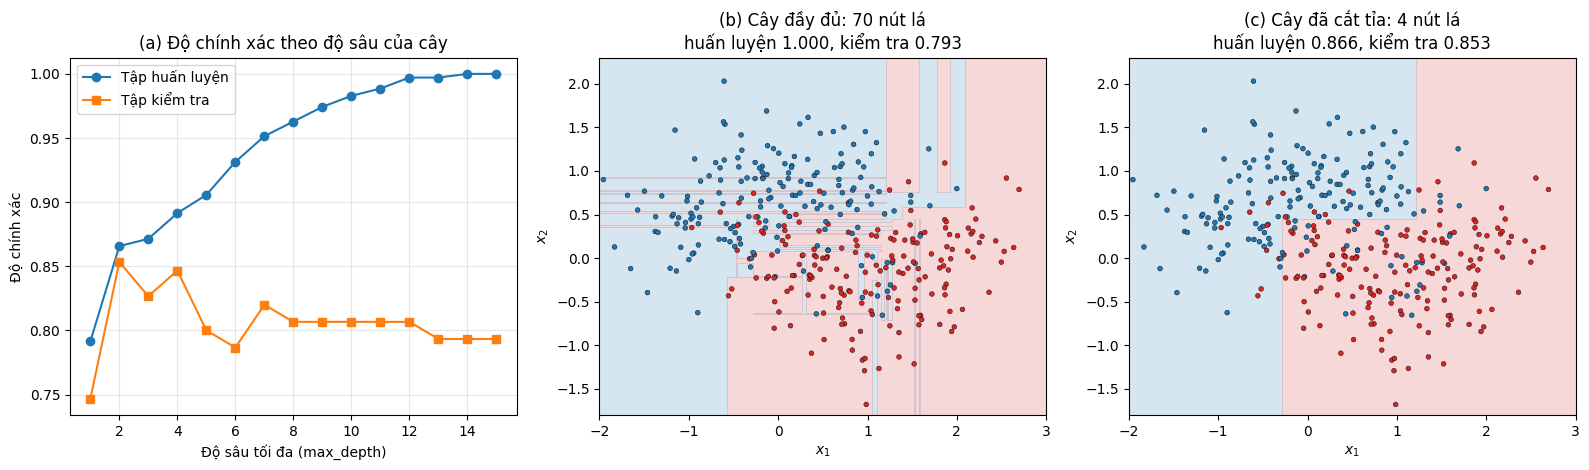

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].plot(depths, train_scores, 'o-', label='Tập huấn luyện')
axes[0].plot(depths, test_scores, 's-', label='Tập kiểm tra')
axes[0].set_xlabel('Độ sâu tối đa (max_depth)'); axes[0].set_ylabel('Độ chính xác')
axes[0].set_title('(a) Độ chính xác theo độ sâu của cây')
axes[0].legend(); axes[0].grid(alpha=0.3)

xx, yy = np.meshgrid(np.linspace(-2, 3, 400), np.linspace(-1.8, 2.3, 400))
for ax, tree, title in [(axes[1], full_tree, '(b) Cây đầy đủ'), (axes[2], pruned_tree, '(c) Cây đã cắt tỉa')]:
    zz = tree.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=['#1F77B4', '#D62728'], alpha=0.18)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=np.array(['#1F77B4', '#D62728'])[y_train], s=12,
               edgecolors='k', linewidths=0.3)
    ax.set_title('%s: %d nút lá\nhuấn luyện %.3f, kiểm tra %.3f'
                 % (title, tree.get_n_leaves(), tree.score(X_train, y_train), tree.score(X_test, y_test)))
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
fig.tight_layout()
fig.savefig(IMAGES / 'tree_overfitting.png', dpi=150)